# CS376 Programming HW 2

## Part 1: Train Cifar10 Dataset

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

2026-03-03 19:43:54.930931: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-03 19:43:56.871255: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-03 19:44:47.670434: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

### Get data from keras

In [15]:
(x_train_cifar10, y_train_cifar10), (x_test_cifar10, y_test_cifar10) = tf.keras.datasets.cifar10.load_data()

/mnt/d/Projects/Digipen/2026Spring/CS376/.venv/lib/python3.12/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


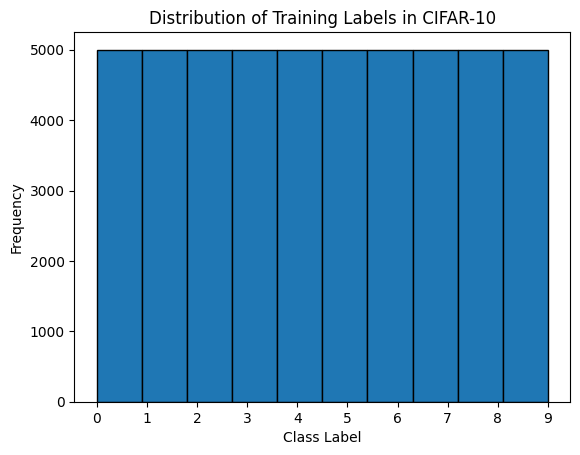

In [16]:
# Check training data distribution using a histogram
import matplotlib.pyplot as plt
plt.hist(y_train_cifar10, bins=10, edgecolor='black')
plt.title('Distribution of Training Labels in CIFAR-10')
plt.xlabel('Class Label')
plt.ylabel('Frequency')
plt.xticks(range(10))
plt.show()

They show perfectly identical distributions, so it doesn't seem necessary to perform any post-processing.

- Show some example images

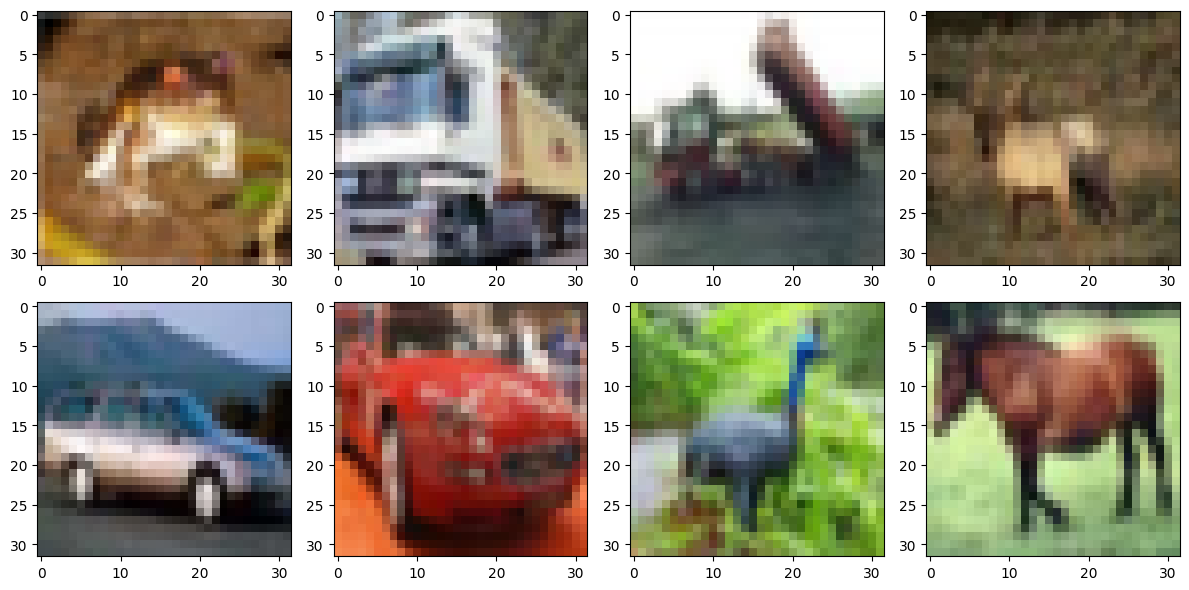

In [17]:
import matplotlib.pyplot as plt

N = len(x_train_cifar10[:8])
rows, cols = 2, 4

fig, axes = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
axes = axes.ravel()

for i, ax in enumerate(axes):
    if i < N:
        img = x_train_cifar10[i]
        ax.imshow(img)

plt.tight_layout()
plt.show()

Nomalize image values

In [18]:
x_train = x_train_cifar10.astype("float32") / 255.0
x_test  = x_test_cifar10.astype("float32") / 255.0

### Make simple CNN Layers and train cifar10

In [19]:
model_cifar10 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"), # -> (32, 32, 32)
    tf.keras.layers.MaxPool2D(),

    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"), # -> (16, 16, 64)
    tf.keras.layers.MaxPool2D(),

    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"), # -> (8, 8, 128)
    tf.keras.layers.MaxPool2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax"),
])

model_cifar10.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [21]:
model_cifar10.fit(
    x_train_cifar10, y_train_cifar10,
    validation_split=0.1,
    epochs=20,
    batch_size=128
)

Epoch 1/20
347/352 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5412 - loss: 1.2816

2026-03-03 20:43:57.515099: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_957', 128 bytes spill stores, 128 bytes spill loads



352/352 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.5641 - loss: 1.2274 - val_accuracy: 0.6144 - val_loss: 1.0939
Epoch 2/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6130 - loss: 1.0925 - val_accuracy: 0.6154 - val_loss: 1.1269
Epoch 3/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6459 - loss: 0.9986 - val_accuracy: 0.6608 - val_loss: 0.9836
Epoch 4/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6835 - loss: 0.8971 - val_accuracy: 0.6698 - val_loss: 0.9460
Epoch 5/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7100 - loss: 0.8241 - val_accuracy: 0.6940 - val_loss: 0.9122
Epoch 6/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7329 - loss: 0.7607 - val_accuracy: 0.7018 - val_loss: 0.8680
Epoch 7/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7560 - loss: 0.6960 - val_accuracy: 0.7132 - val_loss: 0.8725
Epoch 8/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7763 - loss: 0.6362 - val_accuracy: 0.7114 - va

In [22]:
model_cifar10.save("cifar10_v0.keras")
model_cifar10 = tf.keras.models.load_model("cifar10_v0.keras")

In [23]:
model_cifar10.evaluate(x_test_cifar10, y_test_cifar10)

2026-03-03 20:44:51.590692: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_100', 16 bytes spill stores, 16 bytes spill loads



313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7149 - loss: 1.1639


[1.1639270782470703, 0.714900016784668]

It currently shows an accuracy of about 71%, which cannot be considered high, but since it is higher than the approximately 10% probability of random guessing, I believe it has achieved at least a baseline result.

## Part 2: Train Cifar100 Dataset

In [5]:
(x_train_cifar100, y_train_cifar100), (x_test_cifar100, y_test_cifar100) = tf.keras.datasets.cifar100.load_data(label_mode="fine")

/mnt/d/Projects/Digipen/2026Spring/CS376/.venv/lib/python3.12/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


It is said that the CIFAR-100 data has two modes: 'coarse,' divided into 20 categories, and 'fine,' divided into 100. Since I am purely curious, I am going to try working with the 'fine' mode to see if a CNN can handle this difficult classification.

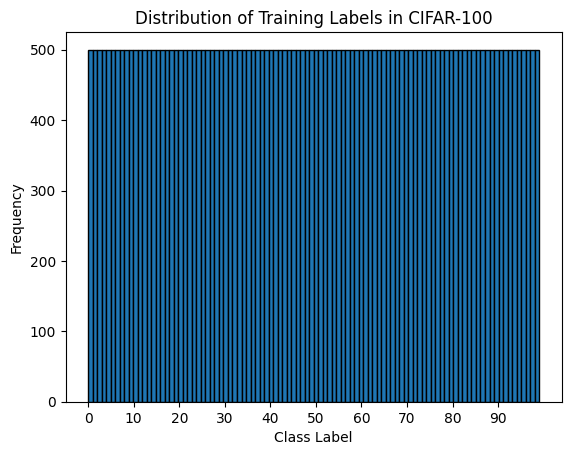

In [11]:
# Check training data distribution using a histogram
import matplotlib.pyplot as plt
plt.hist(y_train_cifar100, bins=100, edgecolor='black')
plt.title('Distribution of Training Labels in CIFAR-100')
plt.xlabel('Class Label')
plt.ylabel('Frequency')
plt.xticks(range(0, 100, 10))
plt.show()

As expected, it shows perfectly uniform results once again.

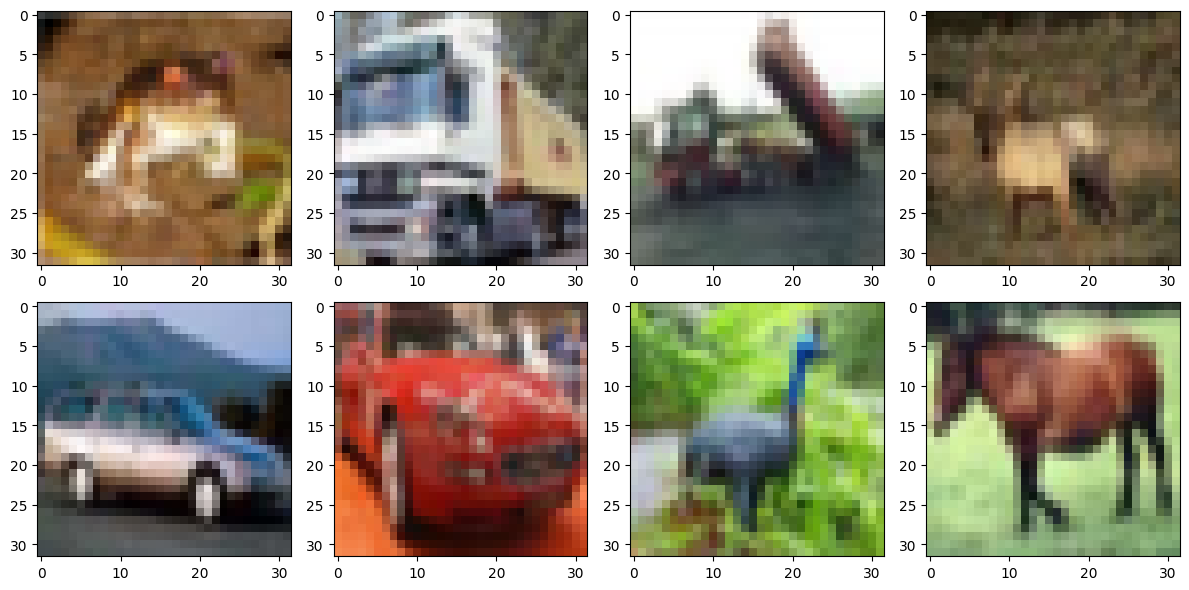

In [12]:
import matplotlib.pyplot as plt
N = len(x_train[:8])
rows, cols = 2, 4

fig, axes = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
axes = axes.ravel()

for i, ax in enumerate(axes):
    if i < N:
        img = x_train[i]
        ax.imshow(img)

plt.tight_layout()
plt.show()

In [13]:
x_train_cifar100 = x_train_cifar100.astype("float32") / 255.0
x_test_cifar100  = x_test_cifar100.astype("float32") / 255.0

### Make CNN Layers and train cifar100

In [3]:
model_cifar100 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.RandomFlip("horizontal"), 
    tf.keras.layers.RandomRotation(0.1, fill_mode="reflect"), 
    tf.keras.layers.RandomZoom(0.1), 
    tf.keras.layers.RandomContrast(0.1),

    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"), # -> (32, 32, 32)
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"), # -> (32, 32, 32)
    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"), # -> (32, 32, 64)
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"), # -> (32, 32, 64)
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPool2D(),

    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"), # -> (16, 16, 128)
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(256, 3, padding="same", activation="relu"), # -> (16, 16, 256)
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPool2D(),

    tf.keras.layers.Conv2D(512, 3, padding="same", activation="relu"), # -> (8, 8, 512)
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(512, 3, padding="same", activation="relu"), # -> (8, 8, 512)
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPool2D(),

    tf.keras.layers.Conv2D(1024, 3, padding="same", activation="relu"), # -> (4, 4, 1024)
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPool2D(),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(512, activation="relu"),    
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(100, activation="softmax"),
])

steps_per_epoch = 352

lr = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.1, decay_steps=steps_per_epoch * 200
)
opt = tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.9, nesterov=True)


model_cifar100.compile(
    optimizer=opt,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [6]:
model_cifar100.fit(
    x_train_cifar100, y_train_cifar100,
    validation_split=0.1,
    epochs=100,
    batch_size=128
)

Epoch 1/100


2026-03-03 19:46:52.174118: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900


352/352 ━━━━━━━━━━━━━━━━━━━━ 38s 80ms/step - accuracy: 0.0706 - loss: 4.0534 - val_accuracy: 0.0448 - val_loss: 4.3951
Epoch 2/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 76ms/step - accuracy: 0.1248 - loss: 3.6914 - val_accuracy: 0.1182 - val_loss: 3.9648
Epoch 3/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.1589 - loss: 3.4927 - val_accuracy: 0.1726 - val_loss: 3.5077
Epoch 4/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.1908 - loss: 3.3215 - val_accuracy: 0.1872 - val_loss: 3.4706
Epoch 5/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.2274 - loss: 3.1278 - val_accuracy: 0.2136 - val_loss: 3.3067
Epoch 6/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.2592 - loss: 2.9555 - val_accuracy: 0.2584 - val_loss: 3.0166
Epoch 7/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.3000 - loss: 2.7771 - val_accuracy: 0.2808 - val_loss: 3.0074
Epoch 8/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.3226 - loss: 2.6445 - val_

In [9]:
model_cifar100.save("cifar100_v0.keras")
model_cifar100 = tf.keras.models.load_model("cifar100_v0.keras")

In [10]:
model_cifar100.evaluate(x_test_cifar100, y_test_cifar100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.6652 - loss: 2.0750


[2.0749659538269043, 0.6651999950408936]

As a result of training with CIFAR-100, as expected, it was more difficult to train than CIFAR-10. By applying various preprocessing techniques to the images, making the CNN deeper, and proceeding while comparing multiple architectural designs, I was barely able to reach the target of 0.60.

## Train Animal10 dataset

In [17]:
from pathlib import Path

CURRENT_DIR = Path.cwd()

ANIMAL10_DIR = CURRENT_DIR / "animal10" / "raw-img"
IMG_SIZE = (224, 224)
SEED = 42
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_raw, holdout_raw = tf.keras.utils.image_dataset_from_directory(
    ANIMAL10_DIR,
    validation_split=0.2,
    subset="both",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=None,
    shuffle=True,
)
class_names = train_raw.class_names

holdout_raw = holdout_raw.shuffle(20000, seed=SEED, reshuffle_each_iteration=False)

holdout_n = tf.data.experimental.cardinality(holdout_raw).numpy()
test_n = holdout_n // 2

test_raw = holdout_raw.take(test_n)
validation_raw  = holdout_raw.skip(test_n)

train_ds = (
    train_raw
    .shuffle(20000, seed=SEED, reshuffle_each_iteration=True)  # train은 epoch마다 섞이게
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
validation_ds = validation_raw.batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = test_raw.batch(BATCH_SIZE).prefetch(AUTOTUNE)

Found 26179 files belonging to 10 classes.
Using 20944 files for training.
Using 5235 files for validation.


For training, I loaded the train and validation sets by splitting them 8:2, and then split the validation set into two again to create the validation and test sets. Through this, I will proceed with the training using a total ratio of 8:1:1 for train:validation:test

In [18]:
translated_class = {"cane": "dog", "cavallo": "horse", "elefante": "elephant", "farfalla": "butterfly", "gallina": "chicken", "gatto": "cat", "mucca": "cow", "pecora": "sheep", "scoiattolo": "squirrel", "ragno": "spiders", "dog": "cane", "cavallo": "horse", "elephant" : "elefante", "butterfly": "farfalla", "chicken": "gallina", "cat": "gatto", "cow": "mucca", "spider": "ragno", "squirrel": "scoiattolo"}

2026-03-03 13:51:29.165425: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:51:29.546322: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:51:32.889862: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:51:36.099751: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:51:38.617199: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:51:38.692045: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:453] ShuffleDatasetV3:806: Filling up shuffle buffer (this may take a while): 5757 of 20000
2026-03-03 13:51:40.033721: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:51:41.078750: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:5

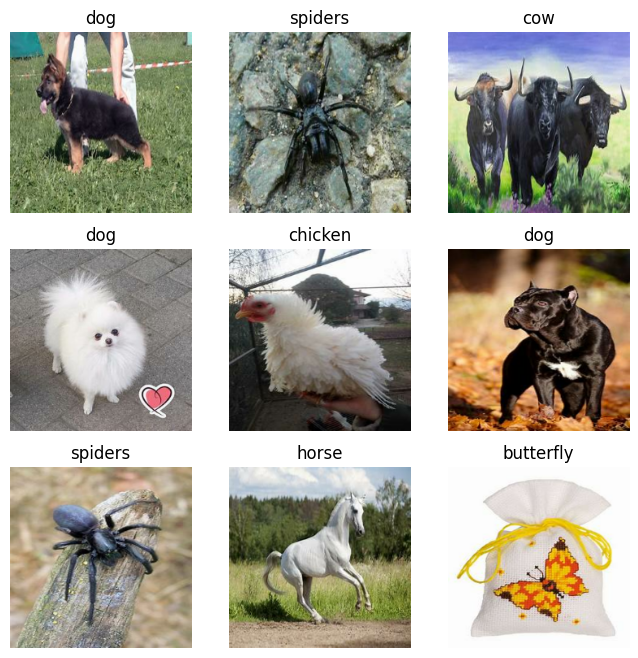

In [19]:
images, labels = next(iter(train_ds))
plt.figure(figsize=(8, 8))

for i in range(9):
    ax = plt.subplot(3, 3, i + 1)

    img = images[i].numpy()
    img = img.astype("uint8")

    plt.imshow(img)
    plt.title(translated_class[class_names[int(labels[i])]])
    plt.axis("off")

plt.show()

Looking at the image set, it does not appear to be a perfectly refined dataset, and given that there are instances such as butterfly patterns on pockets in the case of butterflies, I have a feeling that training will not be easy.

In [20]:
import numpy as np

num_classes = len(class_names)

train_counts = np.zeros(num_classes, dtype=np.int64)

for _, labels in train_ds:  # labels shape: (batch,)
    train_counts += np.bincount(labels.numpy(), minlength=num_classes)

train_counts

2026-03-03 13:52:01.295827: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:02.040903: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:02.299650: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:04.288052: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:05.000449: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:05.219146: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:05.557072: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:07.047116: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:07.365400: W tensorflow/core/lib/png/png_io.cc:95] PNG 

array([3907, 2089, 1190, 1706, 2457, 1365, 1502, 1457, 3796, 1475])

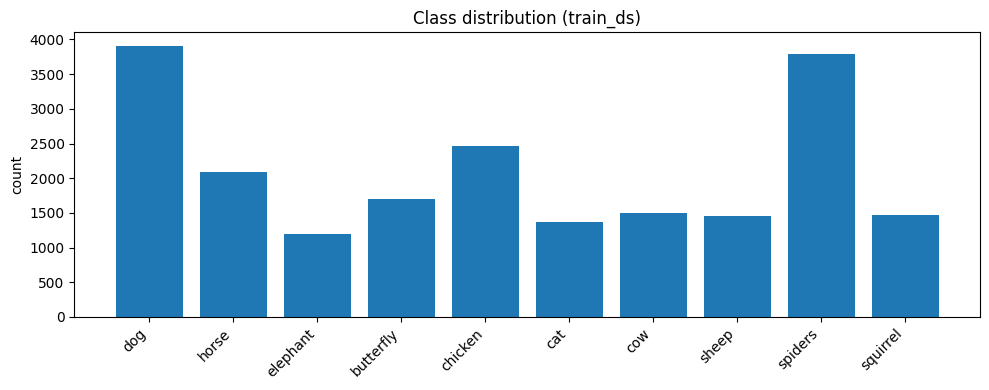

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.bar([translated_class[name] for name in class_names], train_counts)
plt.xticks(rotation=45, ha="right")
plt.ylabel("count")
plt.title("Class distribution (train_ds)")
plt.tight_layout()
plt.show()

The data is not uniform, and while there is a significant difference, with dogs and spiders at about 4,000 and elephants at about 1,000, it is not an extreme disparity. To be honest, I personally believe that even this imbalance should be learned to improve the score (though I am not entirely sure), so I will intentionally proceed without any work to balance the dataset.

### Train baseline model

In [22]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2, fill_mode="reflect"),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])

In [23]:
inputs0 = tf.keras.Input(shape=IMG_SIZE + (3,))
x0 = data_augmentation(inputs0)
x0 = tf.keras.layers.Rescaling(1./255.)(x0)

x0 = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x0)
x0 = tf.keras.layers.MaxPooling2D()(x0) # -> (112, 112, 64)
x0 = tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x0)
x0 = tf.keras.layers.MaxPooling2D()(x0) # -> (56, 56, 128)
x0 = tf.keras.layers.Conv2D(256, 3, padding="same", activation="relu")(x0)
x0 = tf.keras.layers.MaxPooling2D()(x0) # -> (28, 28, 256)
x0 = tf.keras.layers.Conv2D(512, 3, padding="same", activation="relu")(x0)
x0 = tf.keras.layers.MaxPooling2D()(x0) # -> (14, 14, 512)
x0 = tf.keras.layers.Conv2D(1024, 3, padding="same", activation="relu")(x0) 
x0 = tf.keras.layers.MaxPooling2D()(x0) # -> (7, 7, 1024)
x0 = tf.keras.layers.Conv2D(1024, 3, padding="same", activation="relu")(x0)

x0 = tf.keras.layers.GlobalAveragePooling2D()(x0) # -> (1024,)
x0 = tf.keras.layers.Dropout(0.2)(x0)

x0 = tf.keras.layers.Dense(512, activation="relu")(x0)
x0 = tf.keras.layers.Dense(256, activation="relu")(x0)
x0 = tf.keras.layers.Dense(128, activation="relu")(x0)
outputs0 = tf.keras.layers.Dense(num_classes, activation="softmax")(x0)

model_v0 = tf.keras.Model(inputs0, outputs0)

In [24]:
model_v0.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint("animals10_v0.keras", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2),
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
]
history = model_v0.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=100,
    callbacks=callbacks,
)

Epoch 1/100


2026-03-03 13:52:19.915690: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:20.528645: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:20.796028: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:22.602306: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:23.609509: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:24.146125: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:24.453279: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:25.141381: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 13:52:25.467763: W tensorflow/core/lib/png/png_io.cc:95] PNG 

 12/655 ━━━━━━━━━━━━━━━━━━━━ 1:21 126ms/step - accuracy: 0.1429 - loss: 2.2882

2026-03-03 13:52:36.306010: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


654/655 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.1950 - loss: 2.1964

2026-03-03 13:53:57.967050: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.40GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


... (115 outputs left out)

2026-03-03 14:24:51.186629: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.7660 - loss: 0.6886

2026-03-03 14:26:14.062564: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 14:26:14.132383: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 14:26:14.762582: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 107s 140ms/step - accuracy: 0.7699 - loss: 0.6795 - val_accuracy: 0.6765 - val_loss: 0.9524 - learning_rate: 1.0000e-06


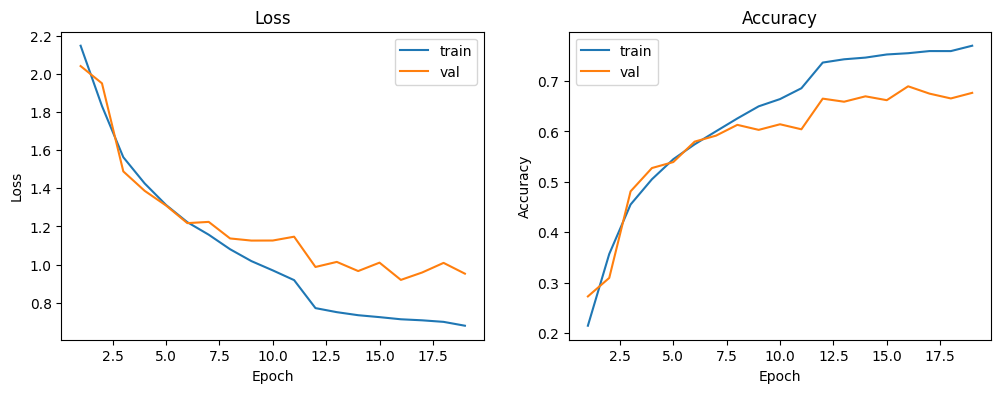

In [25]:
epochs = range(1, len(history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history.history["loss"], label="train")
axes[0].plot(epochs, history.history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(epochs, history.history["accuracy"], label="train")
axes[1].plot(epochs, history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.show()

Although it did not yield the performance I expected compared to the training time invested, it still surpassed the baseline performance, so I will move on for now and try to boost the performance in earnest through transfer learning.

### Train CNN based on ResNet50V2

I chose a model architecture that uses ResNetV2 as the base model and attached a head on top to classify 10 classes. In this approach, ResNet groups CNN layers, which originally sought to find $H(x)$, into blocks and calculates them in the form of $F(x) + x$. This strategy passes the original $x$ forward, allowing the machine learning process to focus on learning the residual change. Through this, the model can easily learn scenarios such as when it simply needs to 'pass through' information, making it easier to train deeper networks compared to architectures like VGG. Furthermore, the Bottleneck structure compresses the number of channels, learns from them, and then expands the channels again, allowing for more efficient training.

In [26]:
base_model = tf.keras.applications.ResNet50V2(
    include_top=False,
    weights="imagenet",
    input_shape=IMG_SIZE + (3,),
)

preprocess_input = tf.keras.applications.resnet_v2.preprocess_input

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = preprocess_input(x)

x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
x = tf.keras.layers.Dense(256, activation="relu")(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

In [27]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint("animals10_v1.keras", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2),
]

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=20,
    callbacks=callbacks,
)

Epoch 1/20


2026-03-03 14:26:44.397995: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 14:26:45.424727: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 14:26:46.339745: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 14:26:47.662626: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 14:26:48.138314: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 14:26:49.130276: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 14:26:49.437971: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 14:26:49.709408: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 14:26:50.874302: W tensorflow/core/lib/png/png_io.cc:95] PNG 

 21/655 ━━━━━━━━━━━━━━━━━━━━ 3:09 300ms/step - accuracy: 0.2505 - loss: 2.1414

2026-03-03 14:27:08.385254: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - accuracy: 0.7645 - loss: 0.7321

2026-03-03 14:30:23.137958: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 14:30:23.202617: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 14:30:23.773802: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


... (115 outputs left out)

2026-03-03 15:38:58.873245: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:38:58.873822: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step - accuracy: 0.9863 - loss: 0.0405

2026-03-03 15:42:15.467253: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:42:15.516303: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:42:16.060633: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 223s 318ms/step - accuracy: 0.9868 - loss: 0.0401 - val_accuracy: 0.9584 - val_loss: 0.1579 - learning_rate: 1.0000e-10


In [28]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])


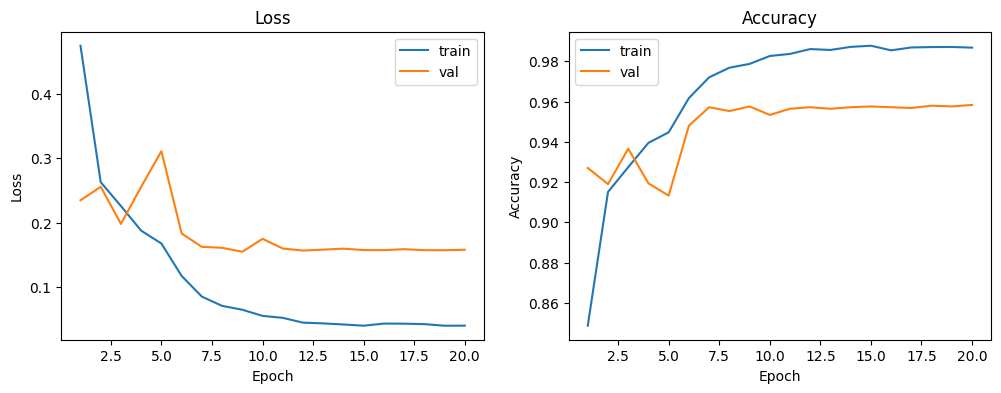

In [29]:
import matplotlib.pyplot as plt

epochs = range(1, len(history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history.history["loss"], label="train")
axes[0].plot(epochs, history.history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(epochs, history.history["accuracy"], label="train")
axes[1].plot(epochs, history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.show()

Looking at the progress after training, it shows a quite peculiar graph. In the early stages of training, it feels as though it is overfitting as the validation score drops, but from a certain point, it rapidly follows the training dataset and reaches a plateau. After leveling off, it can be observed that the two values proceed almost identically without any symptoms of overfitting. A unique point is that the validation set reaches the plateau and stabilizes faster than the moment the training set reaches its plateau.

### Train more variants

This time, I'll make the layers deeper and add a CNN layer before flattening them into one dimension to train on an even deeper network.

In [30]:
inputs2 = tf.keras.Input(shape=IMG_SIZE + (3,))
x2 = data_augmentation(inputs2)
x2 = preprocess_input(x2)

x2 = base_model(x2, training=False)

x2 = tf.keras.layers.Conv2D(1024, 3, padding="same", activation="relu")(x2) # -> (7, 7, 1024)

x2 = tf.keras.layers.GlobalAveragePooling2D()(x2) # -> (1024,)
x2 = tf.keras.layers.Dropout(0.2)(x2)

x2 = tf.keras.layers.Dense(512, activation="relu")(x2)
x2 = tf.keras.layers.Dense(256, activation="relu")(x2)
x2 = tf.keras.layers.Dense(128, activation="relu")(x2)
outputs2 = tf.keras.layers.Dense(num_classes, activation="softmax")(x2)

model_v2 = tf.keras.Model(inputs2, outputs2)

In [31]:
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint("animals10_v2.keras", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2),
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
]

history = model_v2.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=100,
    callbacks=callbacks,
)

Epoch 1/100


2026-03-03 15:42:50.002226: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:42:50.291162: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:42:52.115917: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:42:52.602766: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:42:53.016042: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:42:53.477676: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:42:55.010421: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:42:55.496356: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:42:56.715183: W tensorflow/core/lib/png/png_io.cc:95] PNG 

  2/655 ━━━━━━━━━━━━━━━━━━━━ 3:33 326ms/step - accuracy: 0.2109 - loss: 2.3094 

2026-03-03 15:43:04.717292: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 338ms/step - accuracy: 0.9255 - loss: 0.2691

2026-03-03 15:46:45.459848: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.52GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-03-03 15:46:48.599956: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:46:48.662893: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 15:46:49.271691: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


... (81 outputs left out)

2026-03-03 16:37:45.149222: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - accuracy: 0.9913 - loss: 0.0281

2026-03-03 16:41:21.912317: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:41:21.981185: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:41:22.664712: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 250s 358ms/step - accuracy: 0.9918 - loss: 0.0255 - val_accuracy: 0.9549 - val_loss: 0.1842 - learning_rate: 1.0000e-06


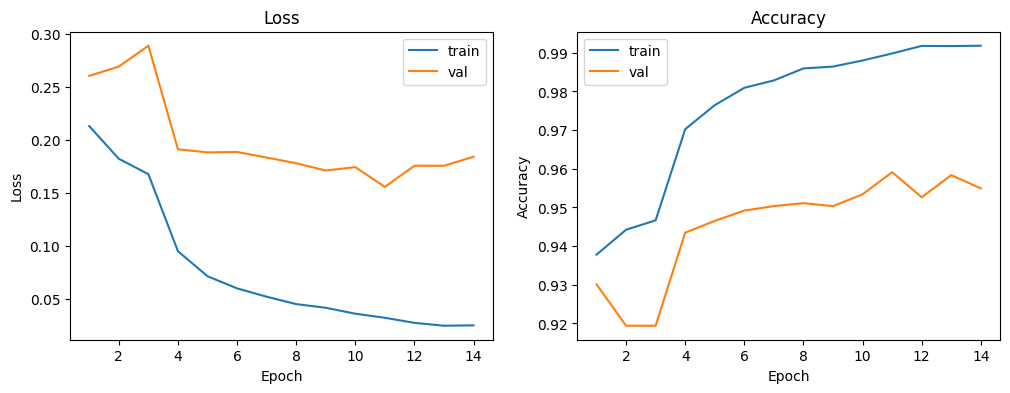

In [32]:
epochs = range(1, len(history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history.history["loss"], label="train")
axes[0].plot(epochs, history.history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(epochs, history.history["accuracy"], label="train")
axes[1].plot(epochs, history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.show()

Contrary to expectations, it is showing worse performance than the base model. Seeing that it has reached a plateau in a way that feels different from overfitting, I get the feeling that it is vulnerable to the noise in the data itself, rather than it being due to a need for more data.

This time, I will make it completely simple and proceed by putting only a softmax at the head.

In [33]:
inputs3 = tf.keras.Input(shape=IMG_SIZE + (3,))
x3 = data_augmentation(inputs3)
x3 = preprocess_input(x3)

x3 = base_model(x3, training=False)


x3 = tf.keras.layers.GlobalAveragePooling2D()(x3) # -> (1024,)
x3 = tf.keras.layers.Dropout(0.2)(x3)

outputs3 = tf.keras.layers.Dense(num_classes, activation="softmax")(x3)

model_v3 = tf.keras.Model(inputs3, outputs3)

In [34]:
model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint("animals10_v3.keras", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2),
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
]
history = model_v3.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=100,
    callbacks=callbacks,
)

Epoch 1/100


2026-03-03 16:41:57.143523: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:41:57.849413: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:41:59.050872: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:41:59.962976: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:42:00.366443: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:42:00.632840: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:42:02.047526: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:42:03.061829: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:42:03.129346: W tensorflow/core/lib/png/png_io.cc:95] PNG 

655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - accuracy: 0.9066 - loss: 0.3359

2026-03-03 16:45:39.480398: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:45:39.559829: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:45:40.304719: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 260s 335ms/step - accuracy: 0.9432 - loss: 0.1915 - val_accuracy: 0.9309 - val_loss: 0.2322 - learning_rate: 1.0000e-04
Epoch 2/100


2026-03-03 16:45:52.175502: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:45:53.821709: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:45:54.226018: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:45:54.973810: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:45:55.619575: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:45:56.043035: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:45:57.877645: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:45:58.173740: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 16:45:58.229543: W tensorflow/core/lib/png/png_io.cc:95] PNG 

... (85 outputs left out)

2026-03-03 17:59:03.386060: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step - accuracy: 0.9915 - loss: 0.0271

2026-03-03 18:02:17.979722: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:02:18.061668: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:02:18.807287: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 224s 319ms/step - accuracy: 0.9905 - loss: 0.0299 - val_accuracy: 0.9572 - val_loss: 0.1805 - learning_rate: 1.0000e-07


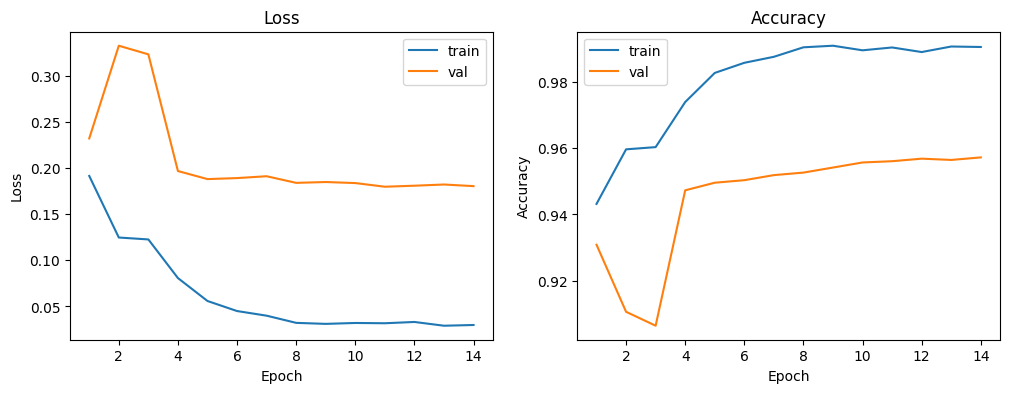

In [35]:
epochs = range(1, len(history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history.history["loss"], label="train")
axes[0].plot(epochs, history.history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(epochs, history.history["accuracy"], label="train")
axes[1].plot(epochs, history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.show()

As expected, it is showing worse performance than the v1 model. I checked to see if perhaps I had gotten the number of neurons completely wrong even for v1, but it seems that the number of neurons I initially set based on intuition was actually quite appropriate.

This time, I will try conducting an experiment by placing a sigmoid function at the end. What I had in mind was to extract 128 features at the end and make it perform inference based on those features.

In [36]:
inputs4 = tf.keras.Input(shape=IMG_SIZE + (3,))
x4 = data_augmentation(inputs4)
x4 = preprocess_input(x4)

x4 = base_model(x4, training=False)

x4 = tf.keras.layers.Conv2D(1024, 3, padding="same", activation="relu")(x4) # -> (7, 7, 1024)

x4 = tf.keras.layers.GlobalAveragePooling2D()(x4) # -> (1024,)
x4 = tf.keras.layers.Dropout(0.2)(x4)

x4 = tf.keras.layers.Dense(512, activation="relu")(x4)
x4 = tf.keras.layers.Dense(256, activation="relu")(x4)
x4 = tf.keras.layers.Dense(128, activation="sigmoid")(x4)
outputs4 = tf.keras.layers.Dense(num_classes, activation="softmax")(x4)

model_v4 = tf.keras.Model(inputs4, outputs4)

In [37]:
model_v4.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint("animals10_v4.keras", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2),
    tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True),
]
history = model_v4.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=100,
    callbacks=callbacks,
)

Epoch 1/100


2026-03-03 18:02:56.597802: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:02:57.114151: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:02:58.151004: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:02:59.908624: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:03:00.147442: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:03:00.151463: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:03:01.566928: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:03:02.954818: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:03:03.074221: W tensorflow/core/lib/png/png_io.cc:95] PNG 

655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step - accuracy: 0.9343 - loss: 0.2967

2026-03-03 18:06:53.879026: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:06:53.949623: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:06:54.549280: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 282s 363ms/step - accuracy: 0.9493 - loss: 0.2060 - val_accuracy: 0.8976 - val_loss: 0.3744 - learning_rate: 1.0000e-04
Epoch 2/100


2026-03-03 18:07:08.580453: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:07:08.580840: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:07:10.201079: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:07:12.035282: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:07:12.589035: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:07:12.877476: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:07:14.453653: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:07:15.216998: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:07:16.210483: W tensorflow/core/lib/png/png_io.cc:95] PNG 

... (13 outputs left out)

2026-03-03 18:15:53.249420: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - accuracy: 0.9599 - loss: 0.1311

2026-03-03 18:19:36.859342: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:19:36.923304: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:19:37.496334: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


655/655 ━━━━━━━━━━━━━━━━━━━━ 250s 357ms/step - accuracy: 0.9613 - loss: 0.1293 - val_accuracy: 0.9045 - val_loss: 0.3554 - learning_rate: 1.0000e-04


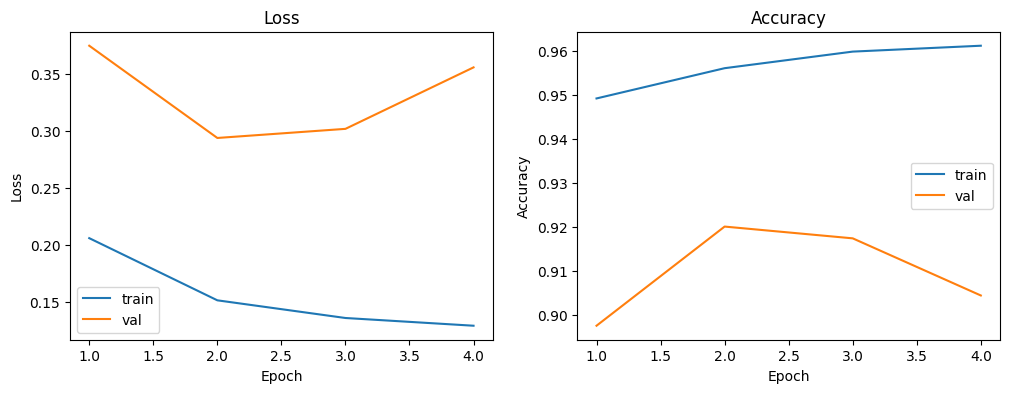

In [38]:
epochs = range(1, len(history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history.history["loss"], label="train")
axes[0].plot(epochs, history.history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(epochs, history.history["accuracy"], label="train")
axes[1].plot(epochs, history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.show()

I had some expectations just in case, but as expected, it showed worse performance compared to ReLU. It feels like when calculating with softmax at the end, the sigmoid layer of this model forcibly flattens the values going into the softmax, actually getting in the way.

## Evaluation

In [39]:
class BaseModelInference(tf.keras.layers.Layer):
    def __init__(self, base_model=None, **kwargs):
        super().__init__(**kwargs)
        self.base_model = base_model
    def call(self, inputs, training=None):
        return self.base_model(inputs, training=False)

model_v0 = tf.keras.models.load_model("animals10_v0.keras")

model_v1 = tf.keras.models.load_model(
    "animals10_v1.keras",
    custom_objects={"BaseModelInference": BaseModelInference},
)


model_v2 = tf.keras.models.load_model(
    "animals10_v2.keras",
    custom_objects={"BaseModelInference": BaseModelInference},
)

model_v3 = tf.keras.models.load_model(
    "animals10_v3.keras",
    custom_objects={"BaseModelInference": BaseModelInference},
)

model_v4 = tf.keras.models.load_model(
    "animals10_v4.keras",
    custom_objects={"BaseModelInference": BaseModelInference},
)

In [40]:
result_v0 = model_v0.evaluate(test_ds)
result_v1 = model_v1.evaluate(test_ds)
result_v2 = model_v2.evaluate(test_ds)
result_v3 = model_v3.evaluate(test_ds)
result_v4 = model_v4.evaluate(test_ds)

2026-03-03 18:20:12.259100: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:20:12.307069: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:20:12.807277: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


81/82 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.6918 - loss: 0.9271

2026-03-03 18:20:18.510118: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 822.26MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-03-03 18:20:18.656575: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.23GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


82/82 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step - accuracy: 0.6825 - loss: 0.9434


2026-03-03 18:20:19.038496: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.30GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-03-03 18:20:19.118622: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.36GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-03-03 18:20:27.906066: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:20:27.959176: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:20:28.467600: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


82/82 ━━━━━━━━━━━━━━━━━━━━ 17s 74ms/step - accuracy: 0.9545 - loss: 0.1534


... (2 outputs left out)

2026-03-03 18:20:50.357485: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:20:50.418302: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:20:50.925027: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


82/82 ━━━━━━━━━━━━━━━━━━━━ 10s 66ms/step - accuracy: 0.9511 - loss: 0.1843


2026-03-03 18:21:00.593077: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:21:00.640705: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-03-03 18:21:01.079762: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


82/82 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - accuracy: 0.9198 - loss: 0.2920


In [41]:
print(f"Model v0 - Loss: {result_v0[0]}, Accuracy: {result_v0[1]}")
print(f"Model v1 - Loss: {result_v1[0]}, Accuracy: {result_v1[1]}")
print(f"Model v2 - Loss: {result_v2[0]}, Accuracy: {result_v2[1]}")
print(f"Model v3 - Loss: {result_v3[0]}, Accuracy: {result_v3[1]}")
print(f"Model v4 - Loss: {result_v4[0]}, Accuracy: {result_v4[1]}")

Model v0 - Loss: 0.9434321522712708, Accuracy: 0.6824608445167542
Model v1 - Loss: 0.1534040868282318, Accuracy: 0.9545280933380127
Model v2 - Loss: 0.18674993515014648, Accuracy: 0.9529995918273926
Model v3 - Loss: 0.18430911004543304, Accuracy: 0.9510890245437622
Model v4 - Loss: 0.2920277416706085, Accuracy: 0.9197554588317871


## Conclusion

Looking at the final results, the v0 model that I trained from scratch myself showed roughly 65% performance, barely surpassing the baseline. However, the model trained using ResNetV2 quickly achieved about 90% performance, and depending on the design of the head, it showed a maximum performance of around 95%, allowing me to confirm the efficiency of transfer learning.